In [1]:
import os
import pandas as pd
import numpy as np
import itertools

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.preprocessing import LabelEncoder

In [2]:
train = pd.read_csv('train.csv', encoding='utf-8')
train_checks = pd.read_csv('train_checks.csv', encoding='utf-8')

### Обзор данных

In [3]:
train.head()

,check_id,name,category,price,count
0,0,*3479755 ТRUF.Конф.кр.корп.гл.вк.шок180г,Чай и сладкое,49.0,2.0
1,0,3408392 ECONTA Мешки д/мусора 30л 30шт,Для дома,21.0,1.0
2,0,3260497 ЯШКИНО Рулет С ВАР.СГУЩ. 200г,Чай и сладкое,39.0,1.0
3,0,3300573 Пакет ПЯТЕРОЧКА 65х40см,Упаковка,4.0,1.0
4,0,3413607 ЗЕР/СЕЛ.Сухари с изюмом 250г,Чай и сладкое,35.0,1.0


In [4]:
train_checks.head()

,check_id,shop_name,datetime,sum
0,0,Не известно,2017-12-30 19:15:00,520.10
1,1,ЕВРОПА,2018-01-03 18:01:29,188.00
2,2,ПродвижениеФарм,2017-12-23 11:37:00,377.00
3,3,Не известно,2017-12-23 14:01:00,1024.00
4,4,ИП Роздухов М. Е.,2018-01-03 12:24:00,1542.16


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13682 entries, 0 to 13681
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   check_id  13682 non-null  int64  
 1   name      13681 non-null  object 
 2   category  13682 non-null  object 
 3   price     13682 non-null  float64
 4   count     13682 non-null  float64
dtypes: float64(2), int64(1), object(2)
memory usage: 534.6+ KB


In [6]:
train_checks.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2042 entries, 0 to 2041
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   check_id   2042 non-null   int64  
 1   shop_name  1967 non-null   object 
 2   datetime   2042 non-null   object 
 3   sum        2042 non-null   float64
dtypes: float64(1), int64(1), object(2)
memory usage: 63.9+ KB


In [7]:
train['category'].unique()

array(['Чай и сладкое', 'Для дома', 'Упаковка', 'Молочка', 'Бакалея',
       'Дети', 'Овощи и фрукты', 'Напитки', 'Здоровье', 'Косметика',
       'Гастрономия', 'Кафе', 'Мясо и птица', 'Хлеб', 'Услуги',
       'Одежда и обувь', 'Рыба', 'Машина', 'Не определена', 'Животные',
       'Кулинария', 'Алкоголь', 'Снеки', 'Табак', 'Компьютер'],
      dtype=object)

In [8]:
len(train['name'].unique())

11313

In [9]:
train_checks['shop_name'].unique()[:10], len(train_checks['shop_name'])

(array(['Не известно', 'ЕВРОПА', 'ПродвижениеФарм', 'ИП Роздухов М. Е.',
        'ОРЕОЛ', 'Агроторг', 'Тандер', nan, 'Новый Книжный М', 'АШАН'],
       dtype=object),
 2042)

### Всего 11313 уникальных названий товаров и 2042 магазина

### Обработаем пропущенные значения

Во многих словах перепутаны регистры, русские/английские символы. Также заменим все "ё" на "е".

In [17]:
train['name'].fillna('', inplace=True)
train.name.str.lower()[25:35]

25     кофе (германия) в зернах "еgоisте =
26     кофе (паулиг) в зернах "мокка" 50 =
27         овощи: кабачки 1кг            =
28        овощи: картофель белый (россия =
29        овощи: картофель красный (росс =
30         овощи: томат тепличный        =
31    печенье (тм ярославские сласти) "о =
32    пп: хлеб/и3д. пончик "радужный" 60 =
33         пп: хлеб/изд. пончики "шарики =
34    сев.молоко: масло слив."крестьянск =
Name: name, dtype: object

In [18]:
train['name'] = train['name'].str.lower()
train['name'] = train['name'].str.replace('a', 'а')
train['name'] = train['name'].str.replace('h', 'н')
train['name'] = train['name'].str.replace('k', 'к')
train['name'] = train['name'].str.replace('b', 'в')
train['name'] = train['name'].str.replace('c', 'с')
train['name'] = train['name'].str.replace('o', 'о')
train['name'] = train['name'].str.replace('p', 'р')
train['name'] = train['name'].str.replace('t', 'т')
train['name'] = train['name'].str.replace('x', 'х')
train['name'] = train['name'].str.replace('y', 'у')
train['name'] = train['name'].str.replace('e', 'е')
train['name'] = train['name'].str.replace('m', 'м')

train.sample(10)

,check_id,name,category,price,count
1357,237,бонусная карта тутси,Услуги,10.00,1.000
9829,2732,лаваш тонкий аппетит,Хлеб,20.09,1.000
12460,3527,"биойогурт ""слобода"" 2,9% 125г вишня",Молочка,29.90,2.000
1886,368,3179370 батон с отрубями пшен.в нар440г,Хлеб,22.90,1.000
7117,2014,3204828 дск яблоко красное 1кг,Овощи и фрукты,109.00,1.355
4389,1205,лосось рубленый с чесноком 120 г ж/б русское море,Гастрономия,75.00,1.000
11361,3068,напиток б/а флэш ап энергия 0.5l пэт,Напитки,52.52,1.000
10744,2935,пирожноепрага,Чай и сладкое,171.02,1.000
4007,1157,31557 кириешки сухар.ржан.с бекон.40г,Снеки,12.90,1.000
4533,1221,корейка имперская к/в в/у 320г ип черкашин,Гастрономия,239.04,1.000


In [19]:
train['name'].str.contains('ё', regex=False).any()
train['name'] = train['name'].str.replace('ё', 'е').replace('Ё', 'Е')

### Поменяем номер продукта, вес, кол-во и т.д. в названии.

In [20]:
train.head()

,check_id,name,category,price,count
0,0,*3479755 тruf.конф.кр.корп.гл.вк.шок180г,Чай и сладкое,49.0,2.0
1,0,3408392 есоnта мешки д/мусора 30л 30шт,Для дома,21.0,1.0
2,0,3260497 яшкино рулет с вар.сгущ. 200г,Чай и сладкое,39.0,1.0
3,0,3300573 пакет пятерочка 65х40см,Упаковка,4.0,1.0
4,0,3413607 зер/сел.сухари с изюмом 250г,Чай и сладкое,35.0,1.0


In [24]:
train['name'] = train['name'].str.replace(u'[^а-яa-z\s]',' ')
train.head()

<ipython-input-24-e590c024ee6a>:1: FutureWarning: The default value of regex will change from True to False in a future version.
  train['name'] = train['name'].str.replace(u'[^а-яa-z\s]',' ')


,check_id,name,category,price,count
0,0,тruf конф кр корп гл вк шок г,Чай и сладкое,49.0,2.0
1,0,есоnта мешки д мусора л шт,Для дома,21.0,1.0
2,0,яшкино рулет с вар сгущ г,Чай и сладкое,39.0,1.0
3,0,пакет пятерочка х см,Упаковка,4.0,1.0
4,0,зер сел сухари с изюмом г,Чай и сладкое,35.0,1.0


In [26]:
train['name'] = train['name'].str.replace('\.', '', regex=True).replace('"', '', regex=True).replace('\(', '', regex=True).replace('\'', '', regex=True) \
                                    .replace('\%', '', regex=True).replace('\*', '', regex=True).replace('=', '', regex=True).replace('\[', '', regex=True) \
                                    .replace('\]', '', regex=True).replace('№', '', regex=True).replace('/', ' ', regex=True).replace('#', '', regex=True) \
                                    .replace(':', '', regex=True).replace('-', '', regex=True).replace(';', '', regex=True).replace(',', '', regex=True) \
                                    .replace('<', '', regex=True).replace('>', '', regex=True).replace('!', '', regex=True).replace(r'\d', '', regex=True) \
                                    .replace('\)', '', regex=True)

train['name'] = train['name'].str.replace(r'\bдля\b', ' ', regex=True).replace(r'\bи\b', ' ', regex=True).replace(r'\bс\b', ' ', regex=True) \
                                    .replace(r'\bв\b', ' ', regex=True).replace(r'\bза\b', ' ', regex=True).replace(r'\bна\b', ' ', regex=True) \
                                    .replace(r'\bшт\b', '', regex=True).replace(r'\bгр\b', '', regex=True).replace(r'\bл\b', '', regex=True) \
                                    .replace(r'\bкг\b', '', regex=True).replace(r'\bг\b', '', regex=True).replace(r'\bиз\b', '', regex=True) \
                                    .replace(r'\bшт\b', '', regex=True).replace(r'\bквм\b', '', regex=True).replace(r'\bруб\b', '', regex=True) \
                                    .replace(r'\bсм\b', '', regex=True)

train['name'] = train['name'].replace('  ', ' ', regex=True)

train[train['name'].str.contains(r'\b\w{1}\b', regex=True)]['name']

1                         есоnта мешки д мусора  
3                              пакет пятерочка х 
14                аlwауs ulтrа прокладки нормал п
17           раnтеnе рrо v бальз оп дополнительны
19                   о рrосомfоrт тампоны nоrмаl 
                           ...                   
13668    пф к к лопатка свиная б кости охл сп гм 
13669                   ветчина оболочке н о вар 
13670                         говядина б к з ч м 
13674                       трк премиумевроаи к  
13676                       скалка деревянная х  
Name: name, Length: 3399, dtype: object

In [27]:
train['name'] = train['name'].replace(r'\b\w{1}\b', '', regex=True)
train.sample(10)

,check_id,name,category,price,count
11328,3058,шоколад аlреn gоld молочный черника,Чай и сладкое,32.49,1.0
12752,3598,булочка арбат,Хлеб,34.99,2.0
11732,3353,продукт кисломол малышок,Молочка,33.90,2.0
1299,226,напиток нести лимон,Напитки,59.00,1.0
9678,2692,разовый полный,Услуги,88.00,1.0
556,101,набор кindеr звезда,Дети,99.00,2.0
4801,1266,кофе карт нуар ориджинал,Чай и сладкое,248.31,1.0
13537,3906,анмаd теа чай черный классически,Чай и сладкое,74.32,1.0
10689,2928,хлеб деревенск,Хлеб,25.90,1.0
6624,1924,большой паровозик тномаs friеnds,Дети,174.00,1.0


### Тоже самое сделаем для магазином

А также заменим "null" на не известно.

In [31]:
train_checks.head()

,check_id,shop_name,datetime,sum
0,0,не известно,2017-12-30 19:15:00,520.10
1,1,европа,2018-01-03 18:01:29,188.00
2,2,продвижениефарм,2017-12-23 11:37:00,377.00
3,3,не известно,2017-12-23 14:01:00,1024.00
4,4,ип роздухов м. е.,2018-01-03 12:24:00,1542.16


In [32]:
train_checks['shop_name'] = train_checks['shop_name'].str.lower()
train_checks.sample(10)

,check_id,shop_name,datetime,sum
642,1169,метро кэш энд керри,2017-12-23 16:10:00,15195.29
316,452,воронежнефтепродукт,2018-01-09 13:47:00,1000.00
1331,2508,тк лето,2018-01-16 18:29:00,380.06
1195,2265,здно,2018-01-22 12:28:00,1331.50
112,139,не известно,2017-12-26 16:08:00,4256.00
663,1210,октоблу,2017-11-12 12:02:00,599.00
1757,3394,максидом,2018-01-28 20:57:00,186.00
413,597,не известно,2018-01-10 19:54:00,976.00
817,1440,агроторг,2017-12-05 18:36:00,755.00
250,347,не известно,2017-12-29 21:41:00,2725.49


In [33]:
train_checks.isna().any()
train_checks.fillna('не известно', inplace=True)

### Объединим эти датасеты в один и удалим столбец с суммой чека, так как он не будет влиять на определение категории:

In [37]:
df = train.merge(train_checks, on=["check_id"])
df.head()

,check_id,name,category,price,count,shop_name,datetime,sum
0,0,тruf конф кр корп гл вк шок,Чай и сладкое,49.0,2.0,не известно,2017-12-30 19:15:00,520.1
1,0,есоnта мешки мусора,Для дома,21.0,1.0,не известно,2017-12-30 19:15:00,520.1
2,0,яшкино рулет вар сгущ,Чай и сладкое,39.0,1.0,не известно,2017-12-30 19:15:00,520.1
3,0,пакет пятерочка,Упаковка,4.0,1.0,не известно,2017-12-30 19:15:00,520.1
4,0,зер сел сухари изюмом,Чай и сладкое,35.0,1.0,не известно,2017-12-30 19:15:00,520.1


In [38]:
del df['sum']
df.sample(5)

,check_id,name,category,price,count,shop_name,datetime
607,113,джемпер хl,Одежда и обувь,999.0,1.000,не известно,2018-01-05 15:32:00
5494,1423,филе цб,Мясо и птица,239.0,2.000,не известно,2018-01-16 23:29:00
8808,2394,галетыстартс отруб,Для дома,67.9,0.356,ашан,2018-01-23 11:21:00
4607,1232,крот средство прочистки труб жид,Для дома,49.0,1.000,не известно,2018-01-05 13:53:00
6543,1895,паштет гран мэр классичес,Гастрономия,31.9,1.000,не известно,2018-01-06 22:56:00


### Добавим фичи: время и день недели покупки, а также закодируем таргет переменную:

In [41]:
df['datetime'] = pd.to_datetime(df['datetime'])
df['purchase_hour'] = df['datetime'].dt.hour
df['purchase_weekday'] = df['datetime'].dt.weekday
df.head()

,check_id,name,category,price,count,shop_name,datetime,purchase_hour,purchase_weekday
0,0,тruf конф кр корп гл вк шок,Чай и сладкое,49.0,2.0,не известно,2017-12-30 19:15:00,19,5
1,0,есоnта мешки мусора,Для дома,21.0,1.0,не известно,2017-12-30 19:15:00,19,5
2,0,яшкино рулет вар сгущ,Чай и сладкое,39.0,1.0,не известно,2017-12-30 19:15:00,19,5
3,0,пакет пятерочка,Упаковка,4.0,1.0,не известно,2017-12-30 19:15:00,19,5
4,0,зер сел сухари изюмом,Чай и сладкое,35.0,1.0,не известно,2017-12-30 19:15:00,19,5


In [42]:
y_le = LabelEncoder()
y_train_complete = y_le.fit_transform(df['category'])
df['category_encoded'] = y_train_complete.copy()
df.head()

,check_id,name,category,price,count,shop_name,datetime,purchase_hour,purchase_weekday,category_encoded
0,0,тruf конф кр корп гл вк шок,Чай и сладкое,49.0,2.0,не известно,2017-12-30 19:15:00,19,5,24
1,0,есоnта мешки мусора,Для дома,21.0,1.0,не известно,2017-12-30 19:15:00,19,5,4
2,0,яшкино рулет вар сгущ,Чай и сладкое,39.0,1.0,не известно,2017-12-30 19:15:00,19,5,24
3,0,пакет пятерочка,Упаковка,4.0,1.0,не известно,2017-12-30 19:15:00,19,5,21
4,0,зер сел сухари изюмом,Чай и сладкое,35.0,1.0,не известно,2017-12-30 19:15:00,19,5,24


In [43]:
df['shop_name'] = df['shop_name'].replace('не известно', 'неизвестно')
df['shop_name'] = df['shop_name'].str.replace(u'[^а-яa-z\s -]',' ')

<ipython-input-43-ec73adcae2b3>:2: FutureWarning: The default value of regex will change from True to False in a future version.
  df['shop_name'] = df['shop_name'].str.replace(u'[^а-яa-z\s -]',' ')


### Проигнорируем товары с ценой от 1 тыс. руб. и выше, чтобы создать более четкую картину распределения.

C:\ProgramData\anaconda3\lib\site-packages\seaborn\distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


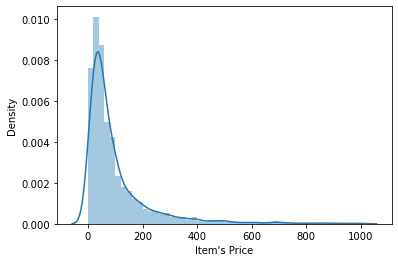

In [45]:
sns.distplot(df[df['price'] < 1000]['price'], bins=50)
plt.xlabel('Item\'s Price');

C:\ProgramData\anaconda3\lib\site-packages\seaborn\distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
C:\ProgramData\anaconda3\lib\site-packages\seaborn\distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
C:\ProgramData\anaconda3\lib\site-packages\seaborn\distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-lev

C:\ProgramData\anaconda3\lib\site-packages\seaborn\distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


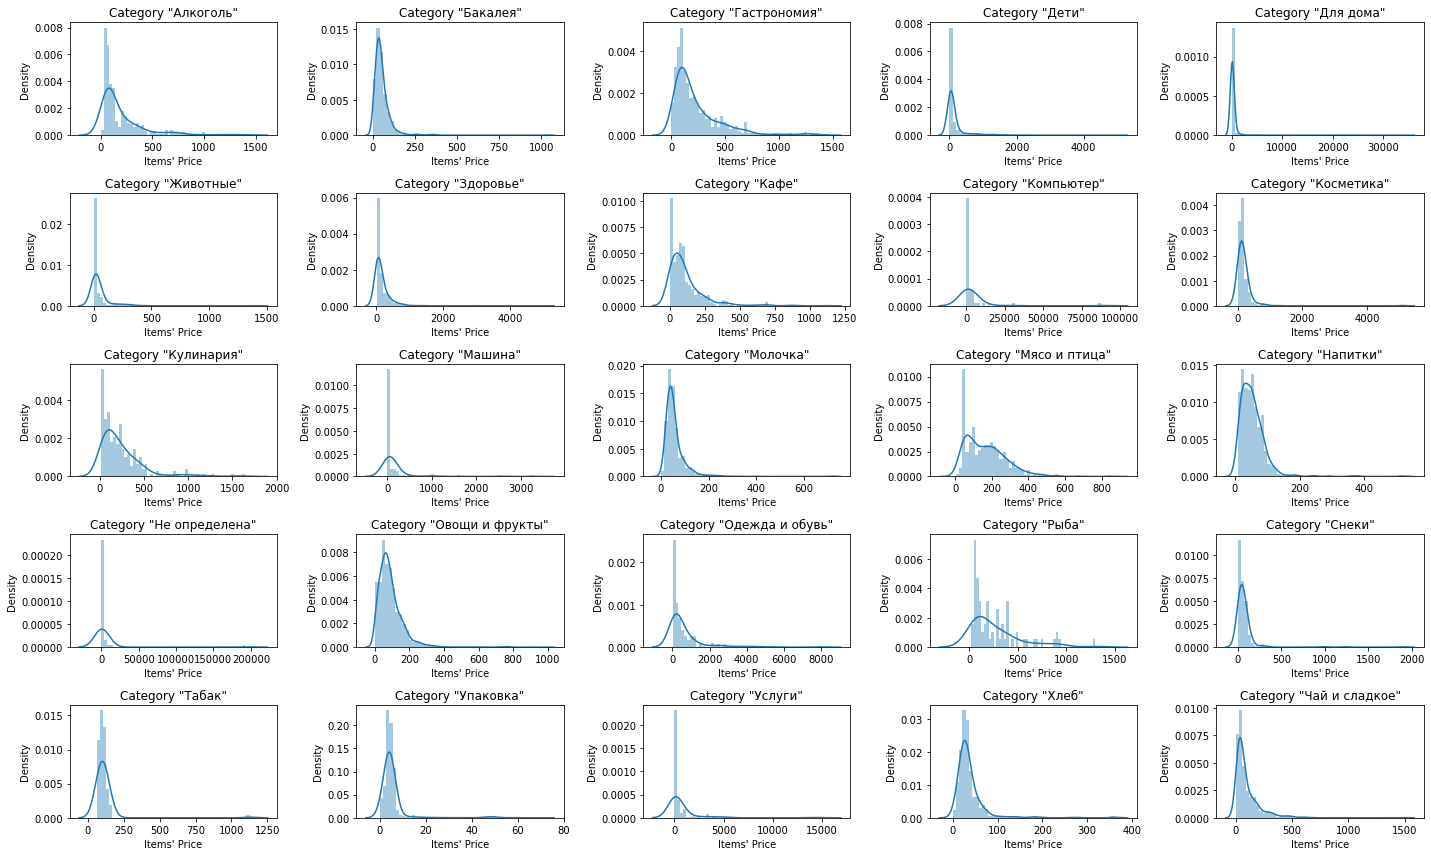

In [46]:
plt.figure(figsize=(20, 12))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.title('Category "' + y_le.classes_[i] + '"')
    sns.distplot(df[df['category_encoded']==i]['price'], bins=50)
    plt.xlabel('Items\' Price')

plt.tight_layout()

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


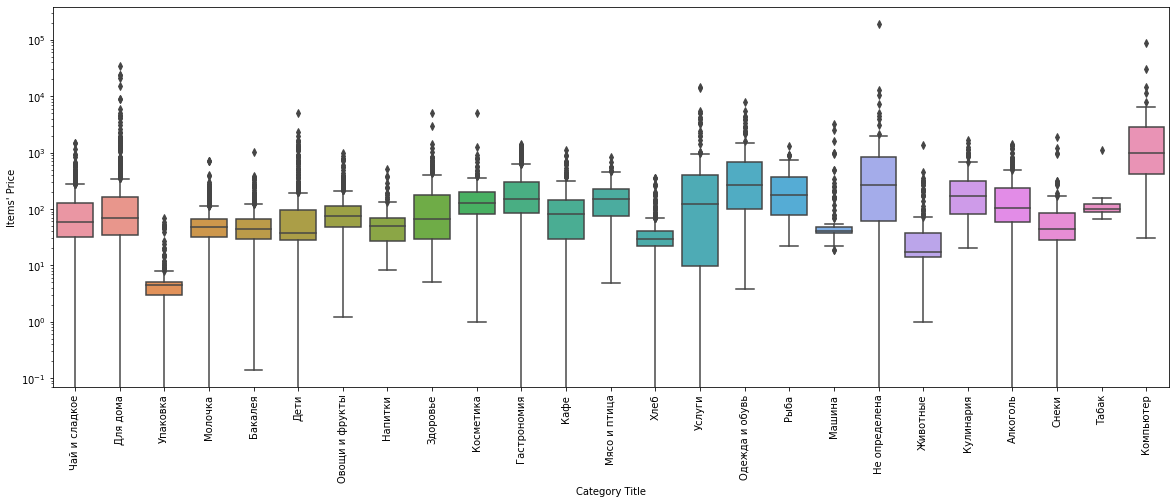

In [ ]:
plt.figure(figsize=(20, 7))
sns.boxplot(df['category'], df['price'])
plt.yscale('log')
plt.xticks(rotation=90)
plt.ylabel('Items\' Price')
plt.xlabel('Category Title');

Покупки по категориям за час и день недели:

In [ ]:
hours = range(24)
weekday_numbers = range(7)
purchase_counts = []

for i in range(25):
    purchase_count = np.zeros((len(weekday_numbers), len(hours)))
    for w, h in itertools.product(weekday_numbers, hours):
        purchase_count[w][h] = df[(df['category_encoded']==i)&\
                                     (df['purchase_weekday']==w)&\
                                     (df['purchase_hour']==h)]['check_id'].count()
    
    purchase_counts.append(purchase_count)

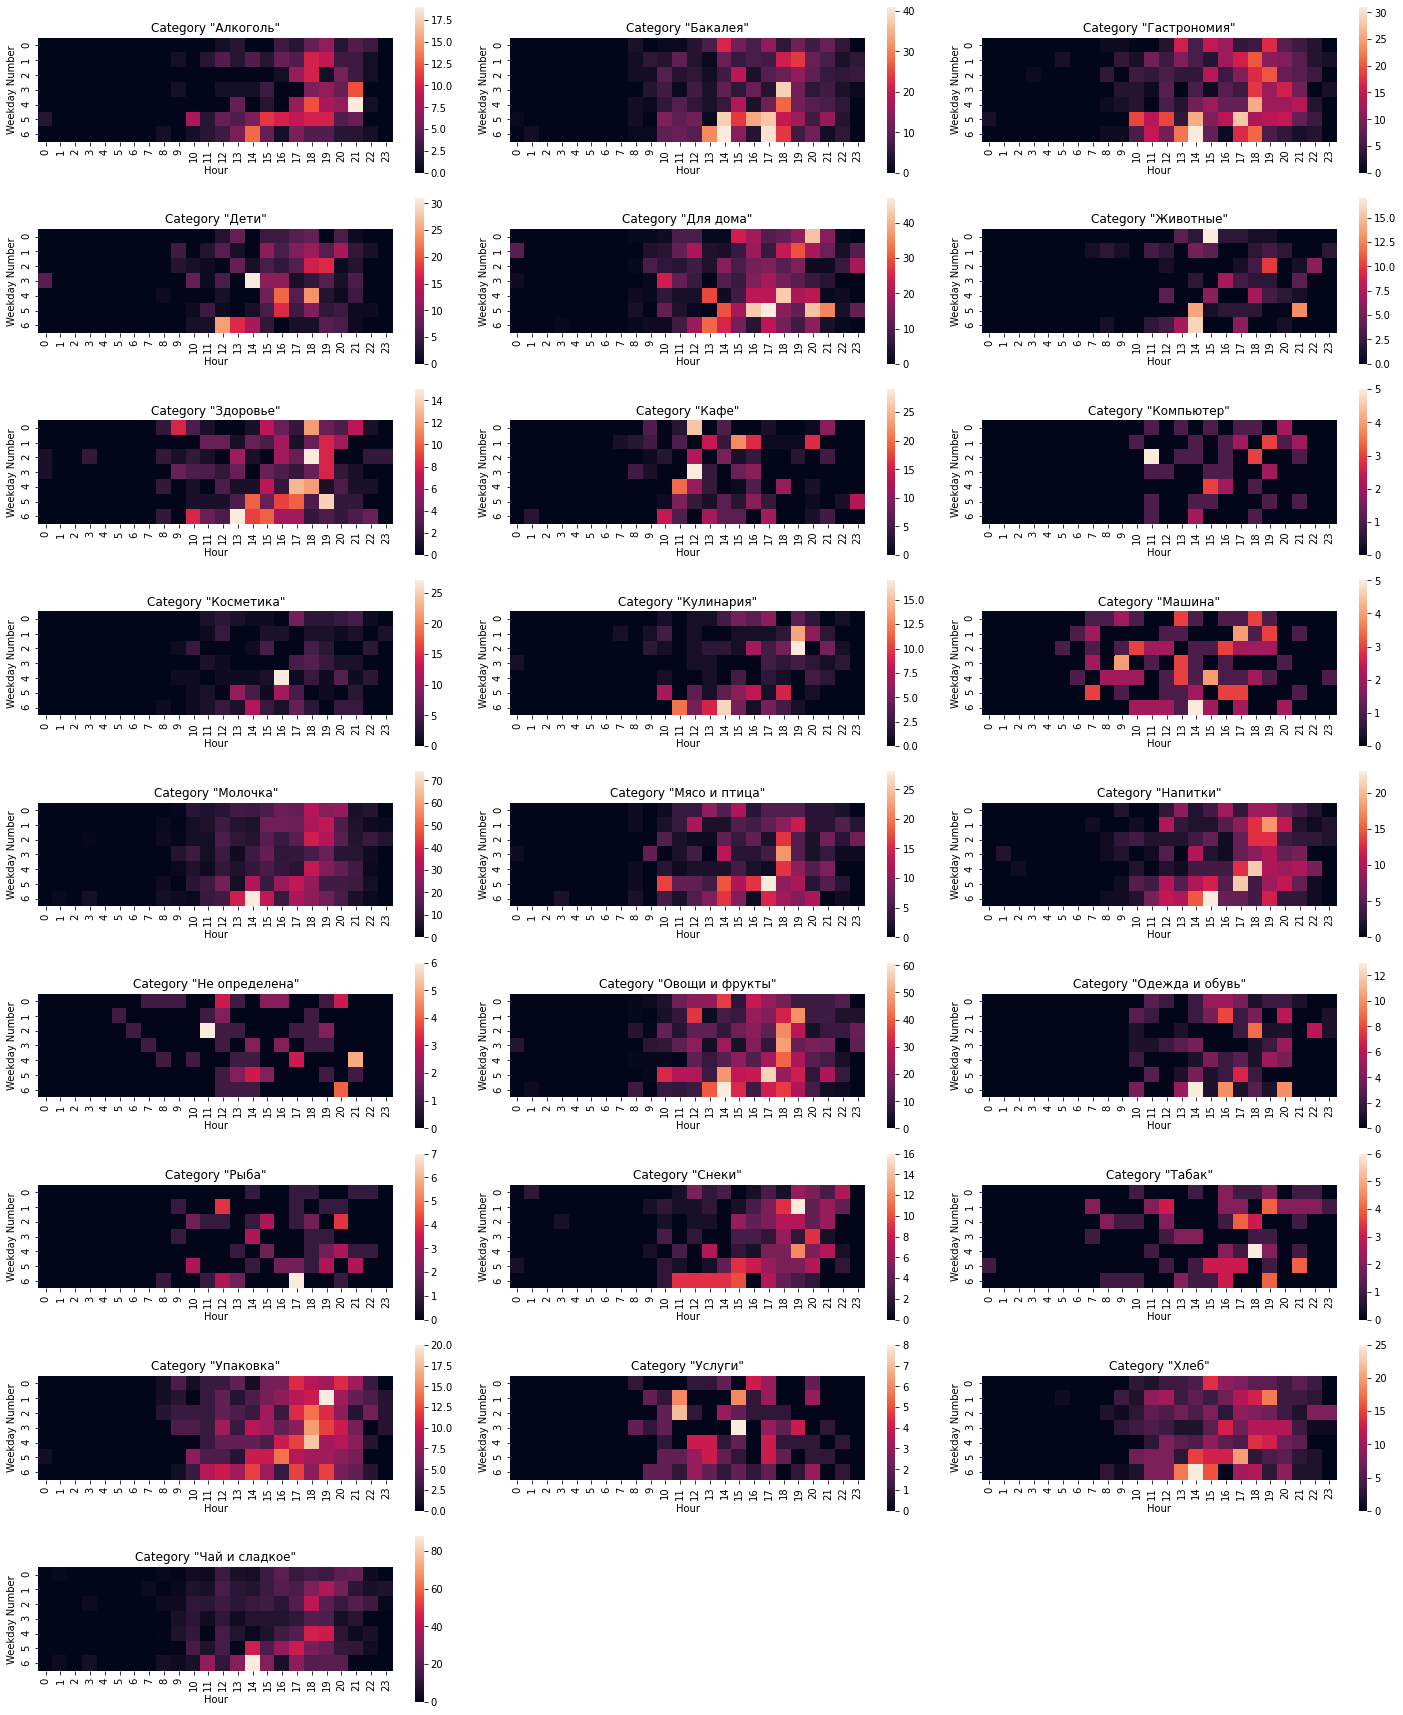

In [ ]:
plt.figure(figsize=(20, 24))

for i in range(25):
    plt.subplot(9, 3, i + 1)
    plt.title('Category "' + y_le.classes_[i] + '"')
    sns.heatmap(purchase_counts[i], square=True)
    plt.xlabel('Hour')
    plt.ylabel('Weekday Number')

plt.tight_layout();

Распределение цен и количества по категориям:

C:\ProgramData\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(
C:\ProgramData\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


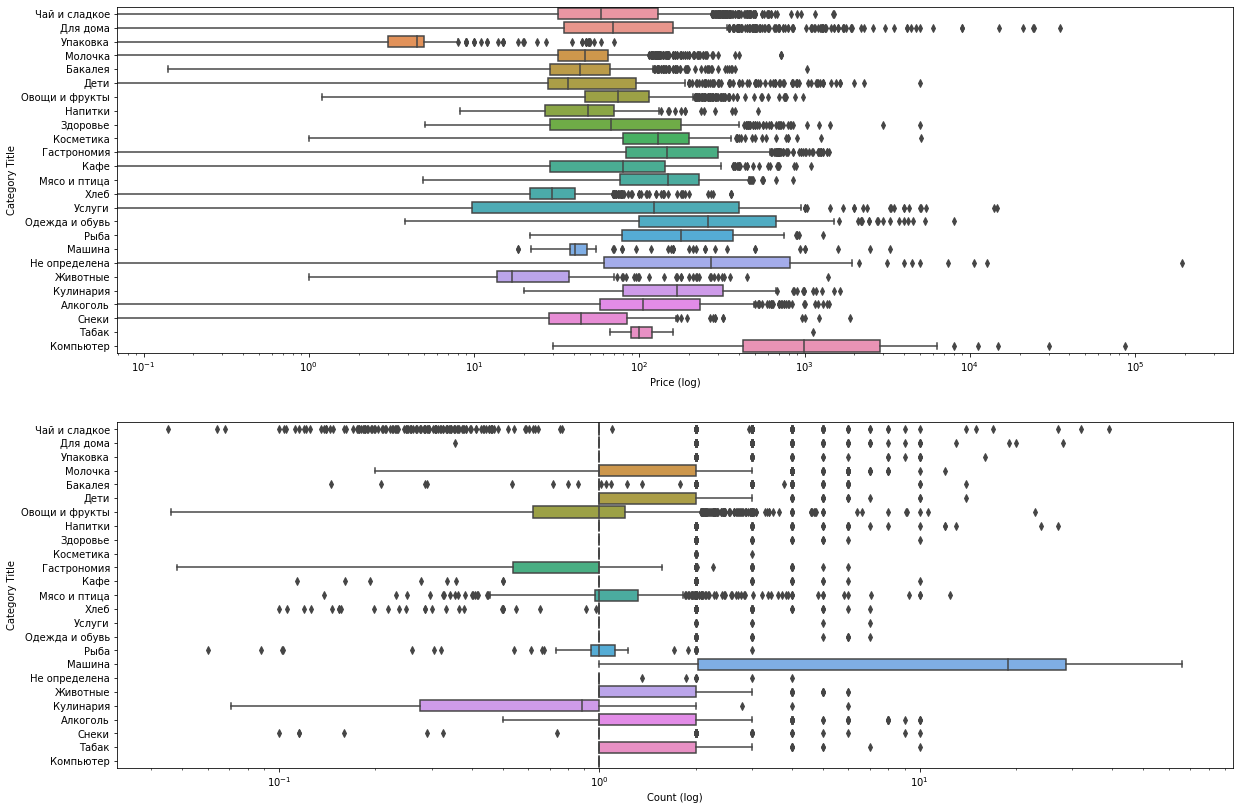

In [47]:
plt.figure(figsize=(20, 14))
plt.subplot(211)
sns.boxplot(df['price'], df['category'])
plt.ylabel('Category Title')
plt.xscale('log')
plt.xlabel('Price (log)')

plt.subplot(212)
sns.boxplot(df['count'], df['category'])
plt.ylabel('Category Title')
plt.xscale('log')
plt.xlabel('Count (log)');

### Построение модели

In [54]:
import pymorphy2

df['name'] = df['name'].astype('U')
df['shop_name'] = df['shop_name'].astype('U')

from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()

X = vectorizer.fit_transform(df['name'])


def f_tokenizer(s):
    morph = pymorphy2.MorphAnalyzer()
    if type(s) == str:
        t = s.split(' ')
    else:
        t = s
    f = []
    for j in t:
        m = morph.parse(j.replace('.',''))
        if len(m) > 0:
            wrd = m[0]
            if wrd.tag.POS not in ('NUMR','PREP','CONJ','PRCL','INTJ'):
                f.append(wrd.normal_form)
    return f

from sklearn.feature_extraction.text import HashingVectorizer

coder = HashingVectorizer(tokenizer=f_tokenizer, n_features=56)
train_df = df[['name', 'count',	'shop_name', 'price',	'purchase_hour',	'purchase_weekday']]

names = train_df.name.tolist()
X = coder.fit_transform(names)
X = X.toarray()
y = df['category_encoded'].values

In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4)

### Случайный лес

In [65]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error

model = RandomForestClassifier(n_estimators = 100, criterion='entropy')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
np.sqrt(mean_squared_error(y_pred, y_test))

print(y_pred)
print(y_test)

[14 12 16 ... 24 14 12]
[14  9 16 ... 24 14  4]


## Градиент

In [66]:
from sklearn.ensemble import GradientBoostingClassifier

model_3 = GradientBoostingClassifier()
model_3.fit(X_train, y_train)

y_pred = model_3.predict(X_test)
np.sqrt(mean_squared_error(y_pred, y_test))

print(y_pred)

print(y_test)

[14 12 12 ... 24 14  1]
[14  9 16 ... 24 14  4]
